In [1]:
!Pip install pandas numpy scikit-learn matplotlib seaborn

In [2]:
import os
import urllib.request

In [3]:
import os
import urllib.request


print("Current working directory:", os.getcwd())

# Create data directory if it doesn't exist
if not os.path.exists('data'):
    os.makedirs('data')
    print("Created 'data' directory")

# Download the file using urllib instead of wget
url = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'
output_path = 'data/CreditScoring.csv'

print(f"\nDownloading from {url}")
urllib.request.urlretrieve(url, output_path)

# Verify the file was downloaded
if os.path.exists(output_path):
    print(f"\nFile successfully downloaded to {output_path}")
    print("File size:", os.path.getsize(output_path), "bytes")

Current working directory: /Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/trees


File successfully downloaded to data/CreditScoring.csv
File size: 182489 bytes


In [4]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv('data/CreditScoring.csv')

In [5]:
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [6]:
df.columns = df.columns.str.lower()

In [7]:
df.columns

Index(['status', 'seniority', 'home', 'time', 'age', 'marital', 'records',
       'job', 'expenses', 'income', 'assets', 'debt', 'amount', 'price'],
      dtype='str')

In [8]:
df.status.value_counts()

status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

In [9]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [10]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [12]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [13]:
df = df[df.status != 'unk'].reset_index(drop=True)

In [14]:
df

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4449,default,1,rent,60,39,married,no,fixed,69,92.0,0.0,0.0,900,1020
4450,ok,22,owner,60,46,married,no,fixed,60,75.0,3000.0,600.0,950,1263
4451,default,0,owner,24,37,married,no,partime,60,90.0,3500.0,0.0,500,963
4452,ok,0,rent,48,23,single,no,freelance,49,140.0,0.0,0.0,550,550


In [15]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [17]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [18]:
del df_train['status']
del df_val['status']
del df_test['status']

In [19]:
## decision trees 

In [20]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

In [21]:
xi = df_train.iloc[0].to_dict()

In [22]:
assess_risk(xi)

'ok'

In [23]:
from sklearn.tree import DecisionTreeClassifier

In [24]:
from sklearn.feature_extraction import DictVectorizer

In [25]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [26]:
dv = DictVectorizer(sparse=False)
x_train = dv.fit_transform(train_dicts)

In [27]:
x_train

array([[3.60e+01, 1.00e+03, 1.00e+04, ..., 0.00e+00, 1.00e+01, 3.60e+01],
       [3.20e+01, 1.10e+03, 0.00e+00, ..., 1.00e+00, 6.00e+00, 4.80e+01],
       [4.00e+01, 1.32e+03, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.80e+01],
       ...,
       [1.90e+01, 4.00e+02, 0.00e+00, ..., 0.00e+00, 1.00e+00, 2.40e+01],
       [4.30e+01, 2.50e+03, 1.80e+04, ..., 0.00e+00, 1.50e+01, 4.80e+01],
       [2.70e+01, 4.50e+02, 5.00e+03, ..., 1.00e+00, 1.20e+01, 4.80e+01]],
      shape=(2672, 29))

In [28]:
dt = DecisionTreeClassifier(max_depth=2, random_state=11) #depth of tree will not be infinite
dt.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",11
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [29]:
val_dicts = df_val.fillna(0).to_dict(orient='records')

In [30]:
x_val = dv.transform(df_val.to_dict(orient='records'))

In [31]:
y_pred = dt.predict_proba(x_val)

In [32]:
from sklearn.metrics import roc_auc_score

In [33]:
roc_auc_score(y_val, y_pred[:, 1])

0.6685264343319367

In [34]:
y_pred = dt.predict_proba(x_train)[:,1]
roc_auc_score(y_train, y_pred)

0.7054989859726213

In [35]:
xi

{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

In [36]:
from sklearn.tree import export_text

In [37]:
print(export_text(dt, feature_names=dv.get_feature_names_out().tolist()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1



In [38]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])

In [39]:
print(df_example.sort_values(by='assets'))

   assets   status
2       0  default
1    2000  default
7    3000  default
5    4000       ok
4    5000       ok
3    5000       ok
0    8000  default
6    9000       ok


In [40]:
Ts = [0, 2000, 3000, 4000, 5000, 8000]

In [41]:
for T in Ts:
    print(T)
    df_left = df_example[df_example.assets <= T]
    df_right = df_example[df_example.assets > T]    

    display(df_left)
    display(df_right)
    print(df_left.status.value_counts(normalize=True))
    print(df_right.status.value_counts(normalize=True))

    print(T)

0


,assets,status
2,0,default


,assets,status
0,8000,default
1,2000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
default    1.0
Name: proportion, dtype: float64
status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64
0
2000


,assets,status
1,2000,default
2,0,default


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
default    1.0
Name: proportion, dtype: float64
status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64
2000
3000


,assets,status
1,2000,default
2,0,default
7,3000,default


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok


status
default    1.0
Name: proportion, dtype: float64
status
ok         0.8
default    0.2
Name: proportion, dtype: float64
3000
4000


,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
default    0.75
ok         0.25
Name: proportion, dtype: float64
status
ok         0.75
default    0.25
Name: proportion, dtype: float64
4000
5000


,assets,status
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


,assets,status
0,8000,default
6,9000,ok


status
default    0.5
ok         0.5
Name: proportion, dtype: float64
status
default    0.5
ok         0.5
Name: proportion, dtype: float64
5000
8000


,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


,assets,status
6,9000,ok


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64
status
ok    1.0
Name: proportion, dtype: float64
8000


In [42]:
T = 4000
df_left = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display(df_left)
print(df_left.status.value_counts(normalize=True))
display(df_right)
print(df_right.status.value_counts(normalize=True))

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


In [43]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])

In [44]:
df_example.sort_values(by='debt')

,assets,debt,status
6,9000,500,ok
1,2000,1000,default
3,5000,1000,ok
2,0,1000,default
5,4000,1000,ok
4,5000,1000,ok
7,3000,2000,default
0,8000,3000,default


In [45]:
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000]
}

for feature, Ts in thresholds.items():
    print('#####################')
    print(feature)
    for T in Ts:
        print(T)
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))

        print()
    print('#####################')

#####################
assets
0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64

3000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
7,3000,2000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok


status
ok         0.8
default    0.2
Name: proportion, dtype: float64

4000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
5,4000,1000,ok
7,3000,2000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
3,5000,1000,ok
4,5000,1000,ok
6,9000,500,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64

5000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.5
ok         0.5
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
6,9000,500,ok


status
default    0.5
ok         0.5
Name: proportion, dtype: float64

8000


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,debt,status
6,9000,500,ok


status
ok    1.0
Name: proportion, dtype: float64

#####################
#####################
debt
500


,assets,debt,status
6,9000,500,ok


status
ok    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
7,3000,2000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64

1000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok


status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
7,3000,2000,default


status
default    1.0
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#####################


## Decision Trees notes

- Decision Trees are non-parametric supervised learning method for classification and regression. 
- Goal is to create a model that predicts value of a target variable by learning simple decision rules ingerred from data features.
- A Piecewise constant approximation 
-  Learn data by approx a since curve with a set of -if else rules', deeper the tree- more complex decision rules and fitter the model. 

## advantages:
- simple to understand and visualise
- little data prep, without normalisation and dummy variables, some support missing values
- cost of using the tree is logarithmic in the number of data poitns used in the three
- able to handle both numerical and categorical data, sci-kit learn does not allow categorical values 
- handles multi-output problems
- white box model- easily explained by boolean logic, black box models e.g. NNs difficult to interpret
- possible to validate a model using stats test, account for reliability
- performs well if assumptions are violated by true model.

## Disadvantages of DTs:
- can create over complex trees that do not generalise  well, overfit and depth is too complex.
- DTs can be unstable because small variations in the data might results in a completely differetn tree being generated, mitigated by using decision trees within an ensemble.
- Predictions are not continious- piecewise constant
- NP complete wants to find the best possible decision tree, (e.g. one iwth lowest impurtiy), searching for the best possible takes a long time.
-  Greedy algo when is committed to the first feature in the first split does not mean its the most efficient tree overall. Can use multiple trees in ensemble learner e.g. random forest, combines predictions than relying on one tree.


In [48]:
## DTs parameter tuning 
- selecting max_depth
- selecting min_samples_leaf

SyntaxError: invalid syntax (3818632399.py, line 2)

In [49]:
for d in [1, 2, 3, 4,5,6,10,15,20,None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(x_train, y_train)

    y_pred = dt.predict_proba(x_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    print(f'depth={d}, AUC={auc:.3f}')


depth=1, AUC=0.606
depth=2, AUC=0.669
depth=3, AUC=0.738
depth=4, AUC=0.759
depth=5, AUC=0.763
depth=6, AUC=0.745
depth=10, AUC=0.691
depth=15, AUC=0.663
depth=20, AUC=0.645
depth=None, AUC=0.667


In [50]:
## best parameters is 4-5
scores = [] 
for d in [4,5,6,10,15,20,None]:
    for s in [1,2,5,10,15,20,100,200,500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(x_train, y_train)

        y_pred = dt.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d,s,auc))
        print(f'depth={d}, min_samples_leaf={s}, AUC={auc:.3f}')

depth=4, min_samples_leaf=1, AUC=0.759


depth=4, min_samples_leaf=2, AUC=0.759
depth=4, min_samples_leaf=5, AUC=0.759
depth=4, min_samples_leaf=10, AUC=0.759
depth=4, min_samples_leaf=15, AUC=0.762
depth=4, min_samples_leaf=20, AUC=0.759
depth=4, min_samples_leaf=100, AUC=0.754
depth=4, min_samples_leaf=200, AUC=0.745
depth=4, min_samples_leaf=500, AUC=0.679
depth=5, min_samples_leaf=1, AUC=0.763
depth=5, min_samples_leaf=2, AUC=0.763
depth=5, min_samples_leaf=5, AUC=0.764
depth=5, min_samples_leaf=10, AUC=0.759
depth=5, min_samples_leaf=15, AUC=0.769
depth=5, min_samples_leaf=20, AUC=0.772
depth=5, min_samples_leaf=100, AUC=0.761
depth=5, min_samples_leaf=200, AUC=0.757
depth=5, min_samples_leaf=500, AUC=0.679
depth=6, min_samples_leaf=1, AUC=0.744
depth=6, min_samples_leaf=2, AUC=0.751
depth=6, min_samples_leaf=5, AUC=0.757
depth=6, min_samples_leaf=10, AUC=0.775
depth=6, min_samples_leaf=15, AUC=0.782
depth=6, min_samples_leaf=20, AUC=0.771
depth=6, min_samples_leaf=100, AUC=0.774
depth=6, min_samples_leaf=200, AUC=0.766


In [51]:
df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'auc'])

In [52]:
df_scores.sort_values(by='auc', ascending=False).head(10)

,max_depth,min_samples_leaf,auc
31,10.0,15,0.789527
58,NaN,15,0.786727
40,15.0,15,0.785662
49,20.0,15,0.784269
32,10.0,20,0.784148
41,15.0,20,0.783642
50,20.0,20,0.782840
22,6.0,15,0.782471
59,NaN,20,0.782123
51,20.0,100,0.777748


In [53]:
df_scores_pivot=df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')

<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

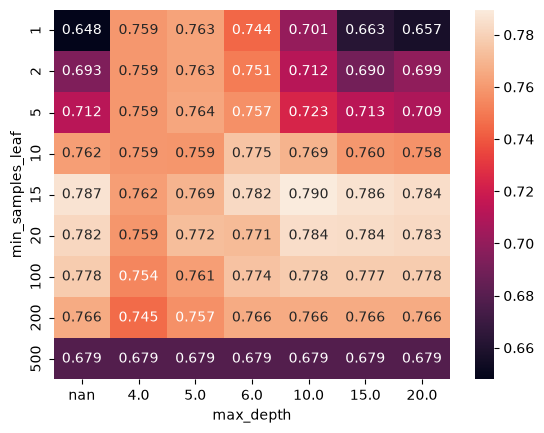

In [54]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [55]:
dt= DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)

In [56]:
dt.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

## ensemble learning and random forest
- board of experts
- ensembling models
- RF- ensembling DTs
- Tuning random forest

In [57]:
from sklearn.ensemble import RandomForestClassifier

In [58]:
rf = RandomForestClassifier(n_estimators=10, random_state=1)
rf.fit(x_train, y_train
      )

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [59]:
y_pred = rf.predict_proba(x_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7754201884187837

In [60]:
rf.predict_proba(x_val[[0]])

array([[0.9, 0.1]])

In [61]:
scores = []
for n in range(10,201,10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(x_train, y_train)

    y_pred = rf.predict_proba(x_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((n,auc))
    print(f'n_estimators={n}, AUC={auc:.3f}')

n_estimators=10, AUC=0.775
n_estimators=20, AUC=0.802
n_estimators=30, AUC=0.814
n_estimators=40, AUC=0.814
n_estimators=50, AUC=0.816
n_estimators=60, AUC=0.815
n_estimators=70, AUC=0.816
n_estimators=80, AUC=0.815
n_estimators=90, AUC=0.816
n_estimators=100, AUC=0.817
n_estimators=110, AUC=0.817
n_estimators=120, AUC=0.817
n_estimators=130, AUC=0.817
n_estimators=140, AUC=0.817
n_estimators=150, AUC=0.817
n_estimators=160, AUC=0.817
n_estimators=170, AUC=0.817
n_estimators=180, AUC=0.817
n_estimators=190, AUC=0.817
n_estimators=200, AUC=0.819


In [62]:
df=pd.DataFrame(scores, columns=['n_estimators', 'auc'])

In [63]:
df

,n_estimators,auc
0,10,0.775420
1,20,0.802336
2,30,0.814097
3,40,0.814384
4,50,0.815822
5,60,0.815278
6,70,0.816116
7,80,0.815268
8,90,0.815795
9,100,0.816703


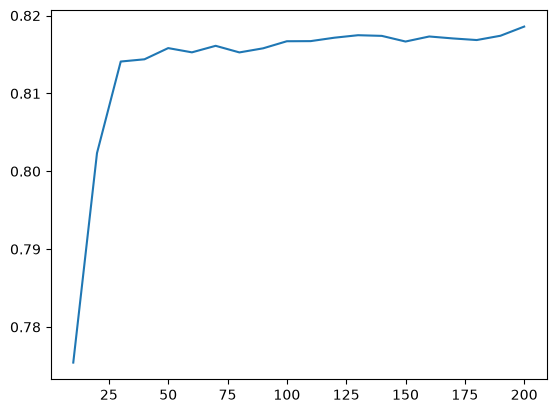

In [64]:
plt.plot(df.n_estimators, df.auc)

In [65]:
scores = []

for d in [5,10,15]:
    for n in range (10,201,10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(x_train, y_train)

        y_pred = rf.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d,n,auc))
        print(f'max_depth={d}, n_estimators={n}, AUC={auc:.3f}')

max_depth=5, n_estimators=10, AUC=0.786
max_depth=5, n_estimators=20, AUC=0.796
max_depth=5, n_estimators=30, AUC=0.799
max_depth=5, n_estimators=40, AUC=0.798
max_depth=5, n_estimators=50, AUC=0.798
max_depth=5, n_estimators=60, AUC=0.800
max_depth=5, n_estimators=70, AUC=0.801
max_depth=5, n_estimators=80, AUC=0.802
max_depth=5, n_estimators=90, AUC=0.802
max_depth=5, n_estimators=100, AUC=0.803
max_depth=5, n_estimators=110, AUC=0.805
max_depth=5, n_estimators=120, AUC=0.805
max_depth=5, n_estimators=130, AUC=0.807
max_depth=5, n_estimators=140, AUC=0.806
max_depth=5, n_estimators=150, AUC=0.806
max_depth=5, n_estimators=160, AUC=0.806
max_depth=5, n_estimators=170, AUC=0.806
max_depth=5, n_estimators=180, AUC=0.806
max_depth=5, n_estimators=190, AUC=0.806
max_depth=5, n_estimators=200, AUC=0.806
max_depth=10, n_estimators=10, AUC=0.791
max_depth=10, n_estimators=20, AUC=0.808
max_depth=10, n_estimators=30, AUC=0.811
max_depth=10, n_estimators=40, AUC=0.817
max_depth=10, n_estimator

In [66]:
columns=['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores.head()

,max_depth,n_estimators,auc
0,5,10,0.786497
1,5,20,0.796493
2,5,30,0.798857
3,5,40,0.798098
4,5,50,0.798188


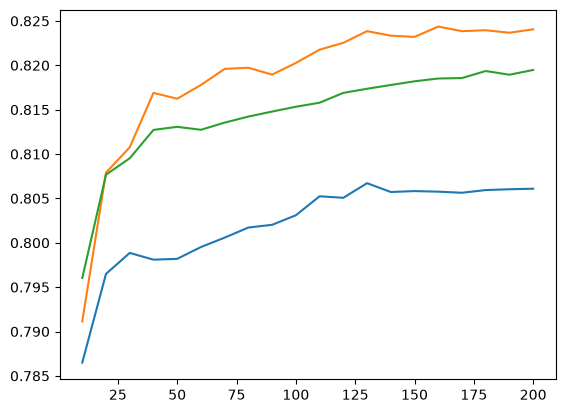

In [67]:
for  d in [5,10,15]:
    df_subset = df_scores[df_scores.max_depth==d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'max_depth={d}')

In [68]:
max_depth = 10 

In [69]:
scores = []

for s in [1,3,5,10,50]:
    for n in range(10,201,10):
        rf = RandomForestClassifier(max_depth=max_depth, 
                                    n_estimators=n, min_samples_leaf=s, 
                                    random_state=1)
        rf.fit(x_train, y_train)

        y_pred = rf.predict_proba(x_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((s,n,auc))
        print(f'max_depth={max_depth}, min_samples_leaf={s}, n_estimators={n}, AUC={auc:.3f}')

max_depth=10, min_samples_leaf=1, n_estimators=10, AUC=0.791
max_depth=10, min_samples_leaf=1, n_estimators=20, AUC=0.808
max_depth=10, min_samples_leaf=1, n_estimators=30, AUC=0.811
max_depth=10, min_samples_leaf=1, n_estimators=40, AUC=0.817
max_depth=10, min_samples_leaf=1, n_estimators=50, AUC=0.816
max_depth=10, min_samples_leaf=1, n_estimators=60, AUC=0.818
max_depth=10, min_samples_leaf=1, n_estimators=70, AUC=0.820
max_depth=10, min_samples_leaf=1, n_estimators=80, AUC=0.820
max_depth=10, min_samples_leaf=1, n_estimators=90, AUC=0.819
max_depth=10, min_samples_leaf=1, n_estimators=100, AUC=0.820
max_depth=10, min_samples_leaf=1, n_estimators=110, AUC=0.822
max_depth=10, min_samples_leaf=1, n_estimators=120, AUC=0.823
max_depth=10, min_samples_leaf=1, n_estimators=130, AUC=0.824
max_depth=10, min_samples_leaf=1, n_estimators=140, AUC=0.823
max_depth=10, min_samples_leaf=1, n_estimators=150, AUC=0.823
max_depth=10, min_samples_leaf=1, n_estimators=160, AUC=0.824
max_depth=10, min

In [70]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,min_samples_leaf,n_estimators,auc
0,1,10,0.791138
1,1,20,0.807909
2,1,30,0.810761
3,1,40,0.816894
4,1,50,0.816234
...,...,...,...
95,50,160,0.804555
96,50,170,0.803750
97,50,180,0.803895
98,50,190,0.804216


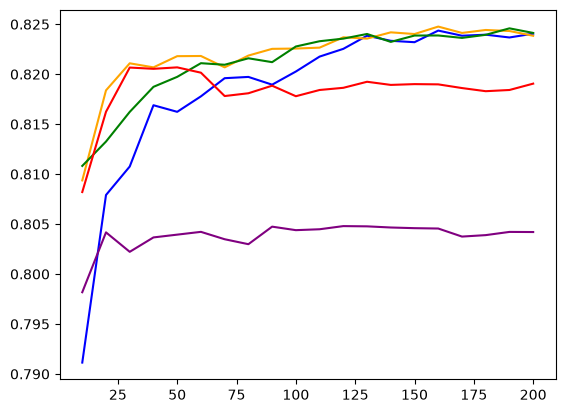

In [71]:
colors = ['blue', 'orange', 'green', 'red', 'purple']
samples_leaf_values = [1,3,5,10,50]

for s, color in zip(samples_leaf_values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf==s]
    plt.plot(df_subset.n_estimators, df_subset.auc, label=f'min_samples_leaf=%d' % s, color=color)

In [72]:
min_samples_leaf = 3
rf = RandomForestClassifier(max_depth=max_depth, n_estimators=100, min_samples_leaf=min_samples_leaf, random_state=1)
rf.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [73]:
## XGBOOST and gradient boosting

In [74]:
!pip install xgboost

In [75]:
import xgboost as xgb

In [76]:
features = dv.get_feature_names_out().tolist()
dtrain = xgb.DMatrix(x_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(x_val, label=y_val, feature_names=features)

In [77]:
xgb_params = {
    'eta': 0.1, #learning rate, how fast the model learns
    'max_depth': 6, #size of trees
    'min_child_weight': 1, #mean samples leaves, number of obs
    'objective': 'binary:logistic', # classification problem, binary classification
    'eval_metric': 'auc', # evaluation metric
    'nthread': 8, #number of threads to use for training
    'seed': 1, #random seed for reproducibility
    'verbosity': 1 #verbosity level, 0=silent, 1=warning, 2=info, 3=debug
}


In [78]:
model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=[(dval, 'val')], early_stopping_rounds=10)

[0]	val-auc:0.77782
[1]	val-auc:0.76912
[2]	val-auc:0.78890
[3]	val-auc:0.79287
[4]	val-auc:0.79493
[5]	val-auc:0.79073
[6]	val-auc:0.79540
[7]	val-auc:0.79592
[8]	val-auc:0.79955
[9]	val-auc:0.80142
[10]	val-auc:0.80233
[11]	val-auc:0.80716
[12]	val-auc:0.80590
[13]	val-auc:0.80593
[14]	val-auc:0.80704
[15]	val-auc:0.80805
[16]	val-auc:0.80971
[17]	val-auc:0.81102
[18]	val-auc:0.81138
[19]	val-auc:0.81157
[20]	val-auc:0.81158
[21]	val-auc:0.81025
[22]	val-auc:0.81080
[23]	val-auc:0.81026
[24]	val-auc:0.81006
[25]	val-auc:0.81049
[26]	val-auc:0.81057
[27]	val-auc:0.81076
[28]	val-auc:0.81164
[29]	val-auc:0.81260
[30]	val-auc:0.81355
[31]	val-auc:0.81400
[32]	val-auc:0.81462
[33]	val-auc:0.81469
[34]	val-auc:0.81608
[35]	val-auc:0.81632
[36]	val-auc:0.81697
[37]	val-auc:0.81730
[38]	val-auc:0.81728
[39]	val-auc:0.81650
[40]	val-auc:0.81642
[41]	val-auc:0.81594
[42]	val-auc:0.81645
[43]	val-auc:0.81698
[44]	val-auc:0.81768
[45]	val-auc:0.81803
[46]	val-auc:0.81873
[47]	val-auc:0.81882
[4

In [80]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8201514857959362

In [81]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [82]:
watchlist

[(<xgboost.core.DMatrix at 0x11c4fae40>, 'train'),
 (<xgboost.core.DMatrix at 0x11c5774d0>, 'val')]

In [106]:
%%capture output 
xgb_params = {
    'eta': 0.1, #learning rate, how fast the model learns
    'max_depth': 6, #size of trees
    'min_child_weight': 1, #mean samples leaves, number of obs
    
    'objective': 'binary:logistic', # classification problem, binary classification
    'eval_metric': 'auc', # evaluation metric
    'nthread': 8, #number of threads to use for training
    
    'seed': 1, #random seed for reproducibility
    'verbosity': 1 #verbosity level, 0=silent, 1=warning, 2=info, 3=debug
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, verbose_eval=5)


In [90]:
s = output.stdout

In [92]:
print(s)

[0]	train-auc:0.86632	val-auc:0.77782
[5]	train-auc:0.90453	val-auc:0.79073
[10]	train-auc:0.92026	val-auc:0.80233
[15]	train-auc:0.92999	val-auc:0.80805
[20]	train-auc:0.93834	val-auc:0.81158
[25]	train-auc:0.94713	val-auc:0.81049
[30]	train-auc:0.95146	val-auc:0.81355
[35]	train-auc:0.95899	val-auc:0.81632
[40]	train-auc:0.96274	val-auc:0.81642
[45]	train-auc:0.96664	val-auc:0.81803
[50]	train-auc:0.96979	val-auc:0.81990
[55]	train-auc:0.97261	val-auc:0.82058
[60]	train-auc:0.97637	val-auc:0.82056
[65]	train-auc:0.97866	val-auc:0.82162
[70]	train-auc:0.98134	val-auc:0.82264
[75]	train-auc:0.98300	val-auc:0.82205
[80]	train-auc:0.98454	val-auc:0.82032
[85]	train-auc:0.98623	val-auc:0.81967
[90]	train-auc:0.98768	val-auc:0.81961
[95]	train-auc:0.98943	val-auc:0.81976
[100]	train-auc:0.99081	val-auc:0.82107
[105]	train-auc:0.99138	val-auc:0.82070
[110]	train-auc:0.99225	val-auc:0.82047
[115]	train-auc:0.99305	val-auc:0.82024
[120]	train-auc:0.99367	val-auc:0.81962
[125]	train-auc:0.9942

In [95]:
line=s.split('\n')[0]

In [96]:
num_iter, train_auc, val_auc = line.split('\t')

In [97]:
int(num_iter.strip('[]'))

0

In [98]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [100]:
df_score=parse_xgb_output(output)

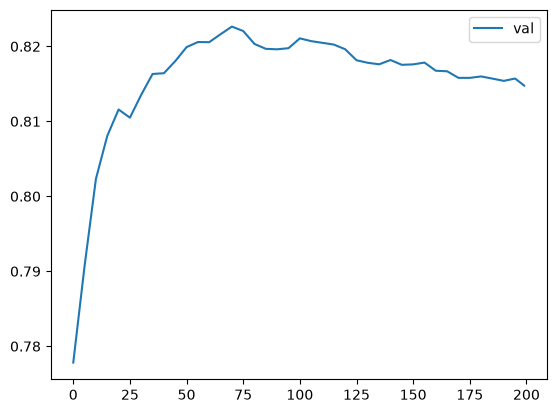

In [103]:
#plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')  
plt.legend()

## parameter tuning 
 - ETA - learning rate, how fast the model learns, size of step
 - Max_depth - 
 - min_child_weight

In [125]:
scores = {}

In [140]:
%%capture output

xgb_params = {
    'eta': 0.01,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [141]:


key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.01'

In [142]:
scores.keys()

dict_keys(['eta=0.01', 'eta=1.0', 'eta=0.3', 'eta=0.1', 'eta=0.05'])

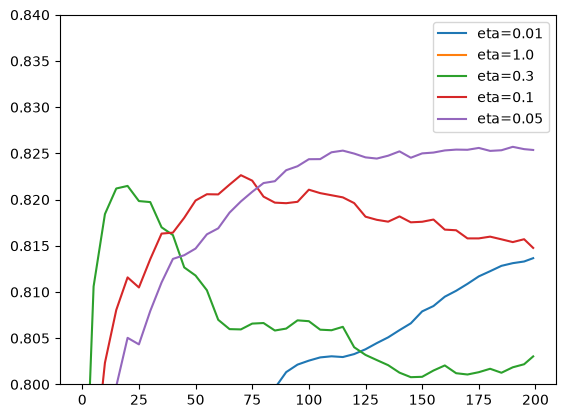

In [ ]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

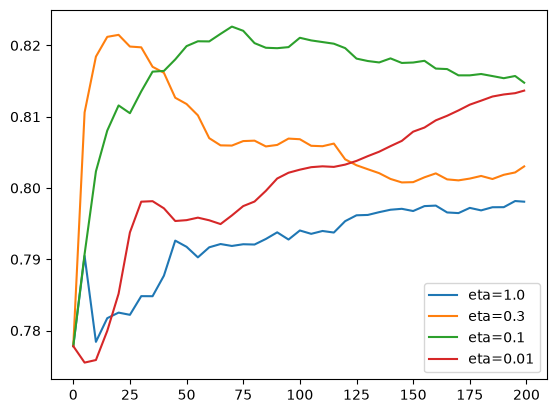

In [145]:
etas = ['eta=1.0','eta=0.3', 'eta=0.1','eta=0.01']
for eta in etas:
    df_score = scores[eta]
    plt.plot(df_score.num_iter, df_score.val_auc, label=eta)
plt.legend()

In [ ]:
scores = {}

In [155]:
%%capture output

xgb_params = {
    'eta': 0.01,
    'max_depth': 4,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [ ]:
del scores['max_depth=10']

In [156]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=4'

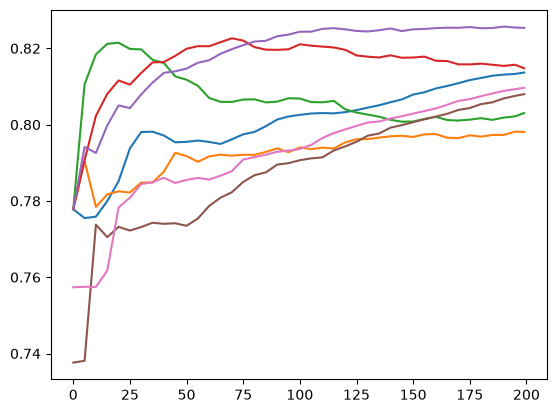

In [159]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)

In [164]:
scores ={}

In [171]:
%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 30,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [173]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=30'

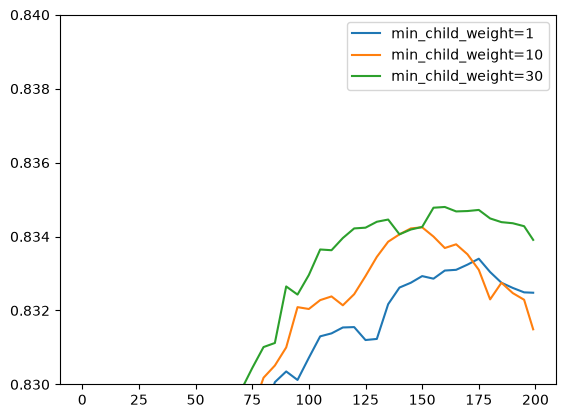

In [179]:
for child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=child_weight)

plt.ylim(0.83, 0.84)
plt.legend()

In [180]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

- subsample and colsample_bytree are two hyperparameters in XGBoost that control the randomness of the training process and help prevent overfitting.
- lamda and alpha

In [181]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [182]:
y_pred = dt.predict_proba(x_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7824919473977379

In [183]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=3,
                            random_state=1)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [184]:
y_pred = rf.predict_proba(x_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8238447845777529

In [185]:

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

In [186]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8335260710566467

In [187]:
df_full_train = df_full_train.reset_index(drop=True)

In [188]:

y_full_train = (df_full_train.status == 'default').astype(int).values

In [189]:
del df_full_train['status']

In [190]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [195]:


features = list(dv.get_feature_names_out())

dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                         feature_names=features)

dtest = xgb.DMatrix(X_test, feature_names=features)

In [196]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [197]:
y_pred = model.predict(dtest)

In [200]:
y_pred[:10]

array([0.2187538 , 0.22356391, 0.0797914 , 0.21547693, 0.3549128 ,
       0.28800038, 0.00819786, 0.02433183, 0.18560964, 0.24188596],
      dtype=float32)

In [198]:
roc_auc_score(y_test, y_pred)

0.8290589414007137